# Decision Tree auf HMEQ

**Ziel:** Vorhersage von `BAD` (1 = Kreditausfall) mit einem Entscheidungsbaum und Vergleich mit der Logistischen Regression.

**Damit der Vergleich fair bleibt**, übernehmen wir aus dem LR-Notebook dieselben Vorab-Regeln, denselben Split (80/20, stratifiziert, `random_state=42`), dieselben 5 CV-Folds, dieselbe Metrik (F1 der Ausfallklasse) und `class_weight="balanced"`.

**Gliederung**
1. Daten, Split und Vorverarbeitung
2. Ungeschnittener Baum: Vergleich Train/Test (Overfitting)
3. Getunter Baum: Vergleich Train/Test
4. Komplexitätskurve (Tiefe gegen F1)
5. Globale Interpretation: Baumstruktur, Regeln, Wichtigkeit
6. Lokale Interpretation: Wie kommt eine einzelne Vorhersage zustande?
7. Vergleich mit der Logistischen Regression
8. Erkenntnisse für das Miro-Board

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import permutation_importance
from sklearn.metrics import f1_score, roc_auc_score, accuracy_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42
TARGET = "BAD"
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

## 1. Daten, Split und Vorverarbeitung

Vorab-Regeln und Split sind identisch mit dem LR-Notebook.

**Unterschiede in der Vorverarbeitung:**
- **Keine Standardisierung.** Ein Baum vergleicht nur Werte mit einer Schwelle ("DEBTINC ≤ 43,7?"). Skalierung oder andere monotone Transformationen ändern daran nichts. Die Schwellen bleiben so in den Originaleinheiten lesbar.
- **Median-Imputation mit Indikatoren** wie bei der LR. Für Bäume ist der Indikator besonders wichtig: Ohne ihn landet ein fehlender Wert auf dem Median, und der Baum kann "fehlt" nicht von "liegt genau beim Median" unterscheiden.
- Kategoriale Merkmale werden wieder One-Hot-kodiert. Der Baum fragt dann "JOB = Office? ja/nein".

In [2]:
df = pd.read_csv(Path("data") / "hmeq.csv")

# Regeln aus der EDA (ohne Datenbezug, daher vor dem Split erlaubt)
df.loc[df["CLAGE"] > 1000, "CLAGE"] = np.nan
df["DEBTINC_fehlt"] = df["DEBTINC"].isna().astype(int)
df["VALUE_fehlt"] = df["VALUE"].isna().astype(int)

X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

num_cols = ["LOAN", "MORTDUE", "VALUE", "YOJ", "DEROG", "DELINQ", "CLAGE", "NINQ", "CLNO", "DEBTINC"]
ind_cols = ["DEBTINC_fehlt", "VALUE_fehlt"]
cat_cols = ["REASON", "JOB"]

def make_prep(scale=False):
    num_steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("ind", "passthrough", ind_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="fehlend")),
                          ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
    ], sparse_threshold=0)   # immer dichte Matrix, das vereinfacht die Interpretation

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print(f"Train: {len(X_train)} Zeilen, Ausfallrate {y_train.mean():.1%}")
print(f"Test:  {len(X_test)} Zeilen, Ausfallrate {y_test.mean():.1%}")

Train: 4768 Zeilen, Ausfallrate 19.9%
Test:  1192 Zeilen, Ausfallrate 20.0%


## 2. Ungeschnittener Baum: Vergleich Train/Test

Zuerst trainieren wir einen Baum **ohne Begrenzung**. Er teilt so lange weiter, bis jedes Blatt rein ist. Das zeigt, wie stark ein Baum zum Auswendiglernen neigt.

In [3]:
def evaluate(model, X, y, name):
    pred = model.predict(X)
    proba = model.predict_proba(X)[:, 1]
    return {"Datensatz": name, "F1": f1_score(y, pred), "ROC-AUC": roc_auc_score(y, proba),
            "Accuracy": accuracy_score(y, pred)}

tree_full = Pipeline([
    ("prep", make_prep()),
    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
])
tree_full.fit(X_train, y_train)

res_full = pd.DataFrame([evaluate(tree_full, X_train, y_train, "Train"),
                         evaluate(tree_full, X_test, y_test, "Test")]).set_index("Datensatz")
display(res_full)
t = tree_full.named_steps["clf"]
print(f"Tiefe: {t.get_depth()}, Blätter: {t.get_n_leaves()}, "
      f"F1-Abstand Train-Test: {res_full.loc['Train', 'F1'] - res_full.loc['Test', 'F1']:.3f}")

,F1,ROC-AUC,Accuracy
Datensatz,,,
Train,1.000,1.000,1.000
Test,0.617,0.747,0.862


Tiefe: 24, Blätter: 459, F1-Abstand Train-Test: 0.383


**Interpretation:** Der ungeschnittene Baum erreicht auf den Trainingsdaten (fast) perfekte Werte, weil er so lange teilt, bis jedes Blatt nur noch eine Klasse enthält. Viele Blätter enthalten dann nur einen oder sehr wenige Kredite. Der Baum hat die Trainingsdaten **auswendig gelernt**, statt allgemeine Regeln zu finden. Der deutliche Abstand zum Test-F1 ist das klassische Zeichen für **Overfitting** (hohe Varianz). Auch die ROC-AUC ist wenig aussagekräftig, denn fast alle Blätter sind rein, und der Baum gibt fast nur Risikowerte von 0 oder 1 aus.

Mit Tiefe und Blattzahl ist das Modell außerdem nicht mehr interpretierbar: Hunderte Regeln kann niemand nachvollziehen. Begrenzung (Pruning) ist also aus zwei Gründen nötig: für die Leistung und für die Erklärbarkeit.

## 3. Getunter Baum: Vergleich Train/Test

Wir begrenzen die Komplexität über zwei Hyperparameter und wählen sie per 5-fold CV auf den Trainingsdaten (Metrik F1, wie bei der LR):
- `max_depth`: maximale Anzahl Fragen bis zur Entscheidung
- `min_samples_leaf`: Mindestzahl Trainingskredite pro Blatt. Das verhindert Regeln, die nur auf wenigen Einzelfällen beruhen.

Liegt der gewählte Wert am Rand des Grids, sollte das Grid erweitert werden. Wir lassen bewusst nur geringe Tiefen zu. Ein Baum mit 12 Ebenen ist für Sachbearbeiter genauso undurchsichtig wie ein Black-Box-Modell.

Beste Parameter: {'clf__max_depth': 4, 'clf__min_samples_leaf': 50}
F1 in der Cross-Validation: 0.683
Tiefe: 4, Blätter: 13


,F1,ROC-AUC,Accuracy
Datensatz,,,
Train,0.688,0.884,0.860
Test,0.672,0.880,0.857


              precision    recall  f1-score   support

kein Ausfall       0.93      0.89      0.91       954
     Ausfall       0.62      0.74      0.67       238

    accuracy                           0.86      1192
   macro avg       0.77      0.81      0.79      1192
weighted avg       0.87      0.86      0.86      1192



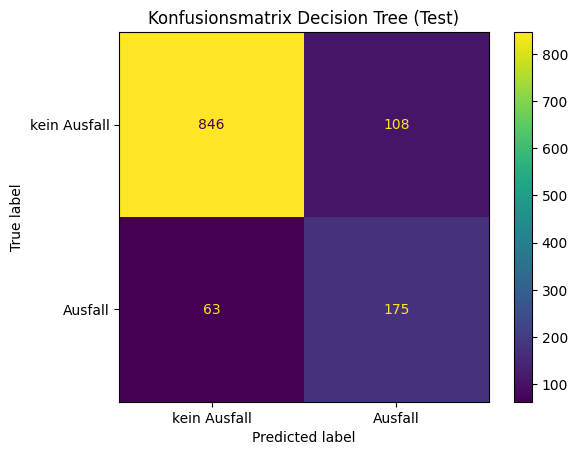

In [4]:
tree_pipe = Pipeline([
    ("prep", make_prep()),
    ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
])
param_grid = {
    "clf__max_depth": [2, 3, 4, 5, 6, 8, 10],
    "clf__min_samples_leaf": [1, 10, 20, 50, 100, 200],
}
grid = GridSearchCV(tree_pipe, param_grid, scoring="f1", cv=cv, n_jobs=-1, return_train_score=True)
grid.fit(X_train, y_train)

model = grid.best_estimator_
tree = model.named_steps["clf"]
print("Beste Parameter:", grid.best_params_)
print(f"F1 in der Cross-Validation: {grid.best_score_:.3f}")
print(f"Tiefe: {tree.get_depth()}, Blätter: {tree.get_n_leaves()}")

results = pd.DataFrame([evaluate(model, X_train, y_train, "Train"),
                        evaluate(model, X_test, y_test, "Test")]).set_index("Datensatz")
display(results)

pred_test = model.predict(X_test)
proba_test = model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred_test, target_names=["kein Ausfall", "Ausfall"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["kein Ausfall", "Ausfall"])
plt.title("Konfusionsmatrix Decision Tree (Test)")
plt.show()

In [5]:
# Robustheit: Wie stark schwanken die Top-Kandidaten? (Bäume sind instabil)
cvres = pd.DataFrame(grid.cv_results_)
cols = ["param_clf__max_depth", "param_clf__min_samples_leaf", "mean_train_score", "mean_test_score", "std_test_score"]
display(cvres.sort_values("mean_test_score", ascending=False)[cols].head(8)
        .rename(columns={"mean_train_score": "F1 Train (CV)", "mean_test_score": "F1 Validierung (CV)",
                         "std_test_score": "Std Validierung"}))

,param_clf__max_depth,param_clf__min_samples_leaf,F1 Train (CV),F1 Validierung (CV),Std Validierung
15,4,50,0.703,0.683,0.013
12,4,1,0.694,0.682,0.012
24,6,1,0.738,0.681,0.012
14,4,20,0.695,0.681,0.016
13,4,10,0.692,0.681,0.012
0,2,1,0.679,0.677,0.007
2,2,20,0.679,0.677,0.007
3,2,50,0.679,0.677,0.007


**Interpretation (bitte mit euren Zahlen prüfen und ergänzen):**
- **Train gegen Test:** Durch die Begrenzung sinkt der Train-F1 gegenüber dem ungeschnittenen Baum deutlich, der Test-F1 steigt aber. Der Abstand zwischen beiden ist jetzt klein. Das Modell generalisiert also, statt auswendig zu lernen.
- **Recall und Precision** der Ausfallklasse wie bei der LR einordnen. `class_weight="balanced"` verschiebt den Baum auch hier zu mehr Fehlalarmen und weniger übersehenen Ausfällen.
- **Tabelle der Top-Kandidaten:** Liegen mehrere Kombinationen innerhalb einer Standardabweichung, ist der Unterschied zufällig. Dann ist der **einfachere Baum** (geringere Tiefe, größere Blätter) vorzuziehen, weil er leichter zu erklären ist.

## 4. Komplexitätskurve

Wie verändern sich Train- und Validierungs-F1, wenn der Baum tiefer wird? Der Validierungs-F1 kommt aus der CV, nicht aus dem Testsatz. `min_samples_leaf` bleibt auf dem gewählten Wert.

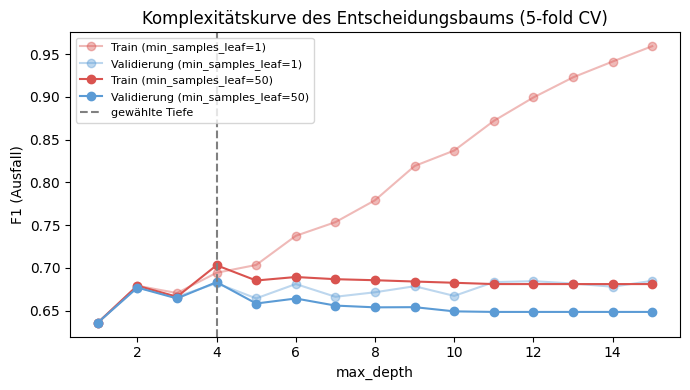

In [6]:
depths = list(range(1, 16))
best_leaf = grid.best_params_["clf__min_samples_leaf"]
curve = []
for d in depths:
    p = Pipeline([("prep", make_prep()),
                  ("clf", DecisionTreeClassifier(max_depth=d, min_samples_leaf=best_leaf,
                                                 class_weight="balanced", random_state=RANDOM_STATE))])
    s = cross_validate(p, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
    curve.append({"Tiefe": d, "Train": s["train_score"].mean(), "Validierung": s["test_score"].mean()})
curve = pd.DataFrame(curve).set_index("Tiefe")

# zum Vergleich: ohne Mindestblattgröße
curve_free = []
for d in depths:
    p = Pipeline([("prep", make_prep()),
                  ("clf", DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE))])
    s = cross_validate(p, X_train, y_train, cv=cv, scoring="f1", return_train_score=True)
    curve_free.append({"Tiefe": d, "Train": s["train_score"].mean(), "Validierung": s["test_score"].mean()})
curve_free = pd.DataFrame(curve_free).set_index("Tiefe")

plt.figure(figsize=(7, 4))
plt.plot(curve_free.index, curve_free["Train"], "o-", color="#d9534f", alpha=0.4, label="Train (min_samples_leaf=1)")
plt.plot(curve_free.index, curve_free["Validierung"], "o-", color="#5b9bd5", alpha=0.4, label="Validierung (min_samples_leaf=1)")
plt.plot(curve.index, curve["Train"], "o-", color="#d9534f", label=f"Train (min_samples_leaf={best_leaf})")
plt.plot(curve.index, curve["Validierung"], "o-", color="#5b9bd5", label=f"Validierung (min_samples_leaf={best_leaf})")
plt.axvline(grid.best_params_["clf__max_depth"], ls="--", color="grey", label="gewählte Tiefe")
plt.xlabel("max_depth"); plt.ylabel("F1 (Ausfall)")
plt.title("Komplexitätskurve des Entscheidungsbaums (5-fold CV)")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation:** Die Kurve zeigt den **Bias-Varianz-Zielkonflikt**.
- *Geringe Tiefe (links):* Train und Validierung liegen niedrig und nah beieinander. Der Baum ist zu einfach (Underfitting, hoher Bias).
- *Mittlere Tiefe:* Die Validierung erreicht ihr Maximum. Hier liegt der gewählte Baum.
- *Große Tiefe (rechts):* Train steigt weiter Richtung 1, die Validierung stagniert oder fällt. Die Lücke ist Overfitting (hohe Varianz).
- `min_samples_leaf` bremst das Overfitting: Die Train-Kurve steigt langsamer, und die Lücke bleibt kleiner.

## 5. Globale Interpretation: Wie entscheidet der Baum?

Ein Entscheidungsbaum ist **intrinsisch erklärbar**: Jede Vorhersage ist eine Folge von Ja/Nein-Fragen von der Wurzel bis zu einem Blatt. Der Risikowert ist der (gewichtete) Anteil an Ausfällen unter den Trainingskrediten in diesem Blatt.

**Lesehilfe für die Grafik:**
- Oben steht die Frage (z. B. `DEBTINC_fehlt <= 0.5` bedeutet "Schuldenquote angegeben"). **Links = ja, rechts = nein.**
- `samples` ist der Anteil der Trainingskredite in diesem Knoten.
- `value` ist die Klassenverteilung **nach Gewichtung** (`class_weight="balanced"`). Sie entspricht also nicht der echten Ausfallrate, deshalb geben wir die echten Raten der Blätter unten zusätzlich aus.
- Die Farbe zeigt die Mehrheitsklasse: orange = kein Ausfall, blau = Ausfall. Je kräftiger die Farbe, desto reiner der Knoten.

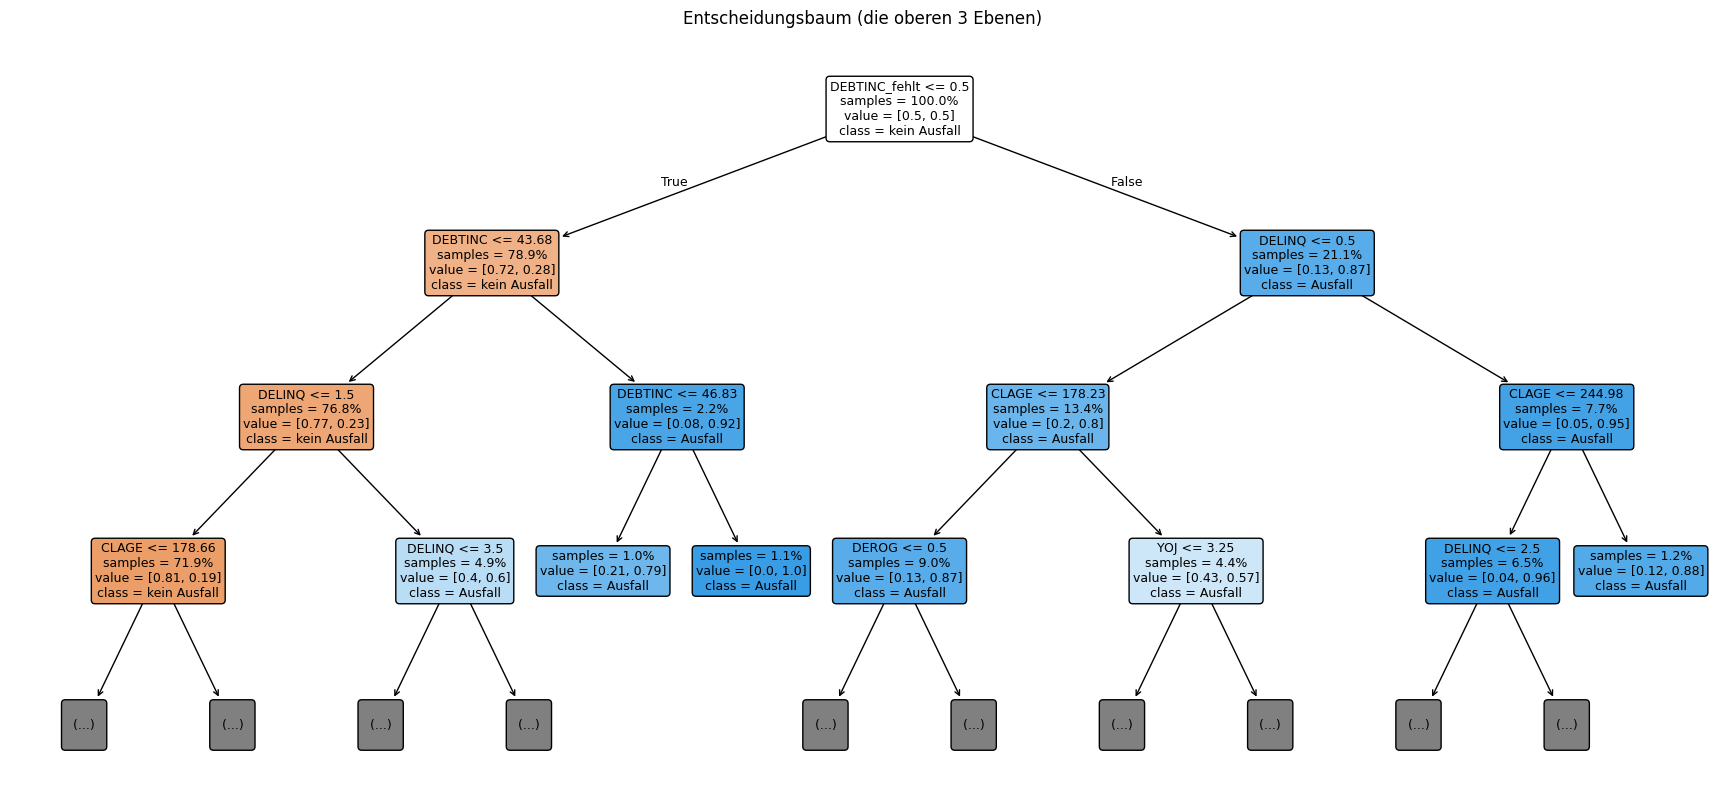

In [7]:
feat_names = [n.split("__", 1)[1] for n in model.named_steps["prep"].get_feature_names_out()]
Z_train = model.named_steps["prep"].transform(X_train)
Z_test = model.named_steps["prep"].transform(X_test)

plt.figure(figsize=(22, 10))
plot_tree(tree, feature_names=feat_names, class_names=["kein Ausfall", "Ausfall"],
          filled=True, proportion=True, rounded=True, impurity=False, precision=2,
          max_depth=3, fontsize=9)
plt.title("Entscheidungsbaum (die oberen 3 Ebenen)")
plt.show()

In [8]:
# Alle Regeln als Text (bei geringer Tiefe gut lesbar)
print(export_text(tree, feature_names=feat_names, decimals=2, show_weights=False))

|--- DEBTINC_fehlt <= 0.50
|   |--- DEBTINC <= 43.68
|   |   |--- DELINQ <= 1.50
|   |   |   |--- CLAGE <= 178.66
|   |   |   |   |--- class: 0
|   |   |   |--- CLAGE >  178.66
|   |   |   |   |--- class: 0
|   |   |--- DELINQ >  1.50
|   |   |   |--- DELINQ <= 3.50
|   |   |   |   |--- class: 1
|   |   |   |--- DELINQ >  3.50
|   |   |   |   |--- class: 1
|   |--- DEBTINC >  43.68
|   |   |--- DEBTINC <= 46.83
|   |   |   |--- class: 1
|   |   |--- DEBTINC >  46.83
|   |   |   |--- class: 1
|--- DEBTINC_fehlt >  0.50
|   |--- DELINQ <= 0.50
|   |   |--- CLAGE <= 178.23
|   |   |   |--- DEROG <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- DEROG >  0.50
|   |   |   |   |--- class: 1
|   |   |--- CLAGE >  178.23
|   |   |   |--- YOJ <= 3.25
|   |   |   |   |--- class: 1
|   |   |   |--- YOJ >  3.25
|   |   |   |   |--- class: 0
|   |--- DELINQ >  0.50
|   |   |--- CLAGE <= 244.98
|   |   |   |--- DELINQ <= 2.50
|   |   |   |   |--- class: 1
|   |   |   |--- DELINQ >  2.50
|   |  

In [9]:
# Echte (ungewichtete) Ausfallrate je Blatt: die "Regeln" des Modells als Tabelle
LABELS = {
    "LOAN": "Kreditbetrag", "MORTDUE": "Offene Hypothek", "VALUE": "Immobilienwert", "YOJ": "Jahre im Job",
    "DEROG": "Schwerwiegende negative Einträge", "DELINQ": "Überfällige Kreditlinien",
    "CLAGE": "Alter älteste Kreditlinie (Monate)", "NINQ": "Neue Kreditanfragen", "CLNO": "Anzahl Kreditlinien",
    "DEBTINC": "Schuldenquote", "DEBTINC_fehlt": "Schuldenquote fehlt", "VALUE_fehlt": "Immobilienwert fehlt",
}

def condition_text(f, thr, goes_left):
    name = feat_names[f]
    if name.endswith("_fehlt"):                     # Indikator 0/1
        base = LABELS[name[:-6]] if name[:-6] in LABELS else name
        return f"{base} {'angegeben' if goes_left else 'fehlt'}"
    if name.startswith(("JOB_", "REASON_")):        # One-Hot 0/1
        var, val = name.split("_", 1)
        return f"{var} {'≠' if goes_left else '='} {val}"
    return f"{LABELS.get(name, name)} {'≤' if goes_left else '>'} {thr:,.2f}"

def leaf_rules(tree):
    t = tree.tree_
    rules = {}
    def walk(node, conds):
        if t.children_left[node] == -1:
            rules[node] = conds
            return
        f, thr = t.feature[node], t.threshold[node]
        walk(t.children_left[node], conds + [condition_text(f, thr, True)])
        walk(t.children_right[node], conds + [condition_text(f, thr, False)])
    walk(0, [])
    return rules

rules = leaf_rules(tree)
leaf_train = tree.apply(Z_train)
leaf_tab = pd.DataFrame({
    "Regel": [" UND ".join(rules[l]) for l in rules],
    "n Train": [int((leaf_train == l).sum()) for l in rules],
    "echte Ausfallrate": [y_train[leaf_train == l].mean() for l in rules],
    "Vorhersage": ["Ausfall" if tree.predict_proba(Z_train[leaf_train == l][:1])[0, 1] >= 0.5 else "kein Ausfall"
                   for l in rules],
}, index=pd.Index(list(rules), name="Blatt")).sort_values("echte Ausfallrate", ascending=False)
with pd.option_context("display.max_colwidth", None):
    display(leaf_tab)

,Regel,n Train,echte Ausfallrate,Vorhersage
Blatt,,,,
11,Schuldenquote angegeben UND Schuldenquote > 43.68 UND Schuldenquote > 46.83,53,1.000,Ausfall
23,Schuldenquote fehlt UND Überfällige Kreditlinien > 0.50 UND Alter älteste Kreditlinie (Monate) ≤ 244.98 UND Überfällige Kreditlinien > 2.50,105,0.933,Ausfall
22,Schuldenquote fehlt UND Überfällige Kreditlinien > 0.50 UND Alter älteste Kreditlinie (Monate) ≤ 244.98 UND Überfällige Kreditlinien ≤ 2.50,206,0.816,Ausfall
16,Schuldenquote fehlt UND Überfällige Kreditlinien ≤ 0.50 UND Alter älteste Kreditlinie (Monate) ≤ 178.23 UND Schwerwiegende negative Einträge > 0.50,83,0.795,Ausfall
24,Schuldenquote fehlt UND Überfällige Kreditlinien > 0.50 UND Alter älteste Kreditlinie (Monate) > 244.98,55,0.655,Ausfall
15,Schuldenquote fehlt UND Überfällige Kreditlinien ≤ 0.50 UND Alter älteste Kreditlinie (Monate) ≤ 178.23 UND Schwerwiegende negative Einträge ≤ 0.50,344,0.584,Ausfall
10,Schuldenquote angegeben UND Schuldenquote > 43.68 UND Schuldenquote ≤ 46.83,50,0.480,Ausfall
8,Schuldenquote angegeben UND Schuldenquote ≤ 43.68 UND Überfällige Kreditlinien > 1.50 UND Überfällige Kreditlinien > 3.50,53,0.472,Ausfall
18,Schuldenquote fehlt UND Überfällige Kreditlinien ≤ 0.50 UND Alter älteste Kreditlinie (Monate) > 178.23 UND Jahre im Job ≤ 3.25,53,0.434,Ausfall


**Wichtigkeit der Merkmale:** Wir vergleichen zwei Maße:
- **Gini-Wichtigkeit** (`feature_importances_`): Wie stark reduziert ein Merkmal die Unreinheit über alle Splits? Sie wird auf den Trainingsdaten berechnet und bevorzugt Merkmale mit vielen möglichen Schwellen (stetige Merkmale).
- **Permutation Importance** auf dem **Testsatz**: Wie stark sinkt die ROC-AUC, wenn man ein Merkmal zufällig durchmischt? Sie misst, worauf sich das Modell bei neuen Daten wirklich stützt. Weil auf den Originalspalten permutiert wird, sind `JOB` und `REASON` automatisch je ein Merkmal.

,Gini (Train),"Permutation, AUC-Verlust (Test)"
DEBTINC_fehlt,0.672,0.227
DEBTINC,0.165,0.043
CLAGE,0.059,0.027
DELINQ,0.095,0.024
YOJ,0.007,0.002
DEROG,0.002,0.001
CLNO,0.000,0.000
JOB,0.000,0.000
MORTDUE,0.000,0.000
LOAN,0.000,0.000


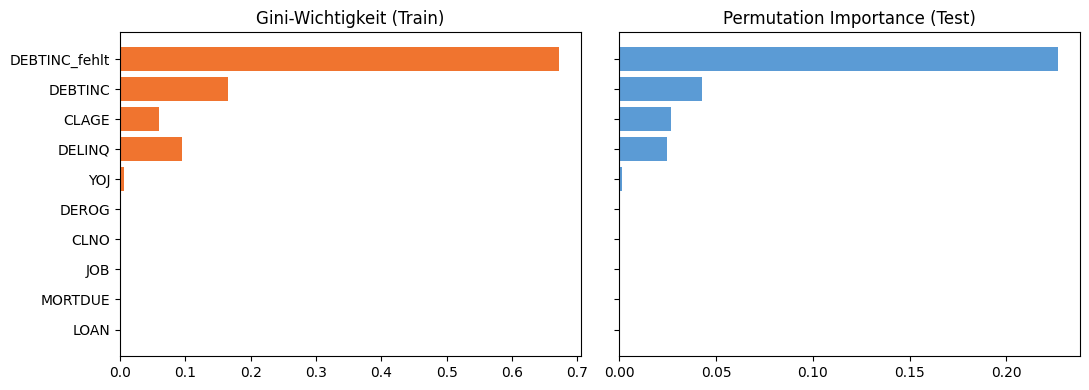

In [10]:
groups = [n.split("_")[0] if n.startswith(("REASON_", "JOB_")) else n for n in feat_names]
gini = pd.Series(tree.feature_importances_, index=groups).groupby(level=0).sum()

perm = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=20,
                              random_state=RANDOM_STATE, n_jobs=-1)
perm = pd.Series(perm.importances_mean, index=X_test.columns)

imp = pd.DataFrame({"Gini (Train)": gini, "Permutation, AUC-Verlust (Test)": perm}).fillna(0)
imp = imp.sort_values("Permutation, AUC-Verlust (Test)", ascending=False)
display(imp)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
top = imp.head(10).iloc[::-1]
ax[0].barh(top.index, top["Gini (Train)"], color="#f0742f"); ax[0].set_title("Gini-Wichtigkeit (Train)")
ax[1].barh(top.index, top["Permutation, AUC-Verlust (Test)"], color="#5b9bd5"); ax[1].set_title("Permutation Importance (Test)")
plt.tight_layout(); plt.show()

**Interpretation der globalen Struktur (bitte mit euren Ergebnissen füllen):**
- *Wurzel:* Welches Merkmal fragt der Baum zuerst? Das ist die Frage, die die Daten am stärksten in "riskant" und "unriskant" trennt. Bei HMEQ ist zu erwarten, dass das `DEBTINC_fehlt` ist. Das wäre konsistent mit der LR (größter mittlerer Beitrag) und der EDA (62 % gegenüber 8,6 % Ausfallrate).
- *Zweite Ebene:* Welche Fragen folgen in den beiden Ästen? Unterscheiden sie sich? Das ist der Kern der **Wechselwirkungen**: Der Baum kann z. B. bei angegebener Schuldenquote nach `DELINQ` fragen und bei fehlender nach etwas ganz anderem. Die LR kann das nicht, sie addiert jeden Effekt unabhängig vom Rest.
- *Blatttabelle:* Welche Regel führt zur höchsten, welche zur niedrigsten Ausfallrate? Gibt es Blätter mit wenigen Trainingskrediten? Deren Rate ist unsicher.
- *Schwellen:* Sind die Schwellen fachlich plausibel (z. B. `DELINQ > 0.5` heißt "mindestens eine überfällige Kreditlinie", `DEBTINC > 43` heißt "hohe Schuldenquote")?
- *Wichtigkeit:* Stimmen Gini und Permutation überein? Merkmale, die nur bei Gini hoch sind, nutzt der Baum für feine Splits, die auf neuen Daten wenig bringen. Merkmale, die im Baum gar nicht vorkommen, haben die Wichtigkeit 0. **Vergleich mit der LR:** Welche Merkmale nutzen beide Modelle, welche nur eines?

## 6. Lokale Interpretation: Wie kommt eine einzelne Vorhersage zustande?

Für einen einzelnen Kredit lässt sich der **Entscheidungspfad** direkt ablesen: die Fragen, die der Kredit durchläuft, und das Blatt, in dem er landet. Die Vorhersage lautet dann sinngemäß: *"Kredite, die diese Bedingungen erfüllen, sind in den Trainingsdaten zu X % ausgefallen."*

Wir nutzen dieselben vier Fallgruppen wie im LR-Notebook (jeweils der Fall mit mittlerem Risikowert der Gruppe). Weil sich die Modelle unterscheiden, sind es nicht unbedingt dieselben Kredite.

In [11]:
y_arr = y_test.to_numpy()

def pick_median_case(mask):
    idx = np.where(mask)[0]
    if len(idx) == 0:
        return None
    order = idx[np.argsort(proba_test[idx], kind="stable")]
    return int(order[len(order) // 2])

has_ind = X_test[ind_cols].to_numpy().sum(axis=1) > 0
cases = {
    "Richtig erkannter Ausfall": pick_median_case((y_arr == 1) & (pred_test == 1) & ~has_ind),
    "Richtig erkannter Nicht-Ausfall": pick_median_case((y_arr == 0) & (pred_test == 0)),
    "Übersehener Ausfall": pick_median_case((y_arr == 1) & (pred_test == 0)),
    "Fehlalarm (guter Kunde als riskant eingestuft)": pick_median_case((y_arr == 0) & (pred_test == 1)),
}

def raw_value_text(name, raw):
    if name.endswith("_fehlt"):
        return ""
    if name.startswith(("JOB_", "REASON_")):
        var = name.split("_", 1)[0]
        return f"   [Wert: {raw[var] if pd.notna(raw[var]) else 'fehlend'}]"
    v = raw[name]
    return "   [Wert: fehlt, ersetzt durch Median]" if pd.isna(v) else f"   [Wert: {v:,.2f}]"

def explain_path(i, title=""):
    t = tree.tree_
    z = Z_test[i]
    raw = X_test.iloc[i]
    node = 0
    print(f"=== {title} (Testzeile {i}) ===")
    step = 1
    while t.children_left[node] != -1:
        f, thr = t.feature[node], t.threshold[node]
        goes_left = z[f] <= thr
        print(f"  {step}. {condition_text(f, thr, goes_left)}{raw_value_text(feat_names[f], raw)}")
        node = t.children_left[node] if goes_left else t.children_right[node]
        step += 1
    in_leaf = leaf_train == node
    print(f"  → Blatt {node}: {in_leaf.sum()} Trainingskredite, davon {y_train[in_leaf].mean():.1%} ausgefallen")
    print(f"  → Risikowert (gewichtet) {proba_test[i]:.2f}, Vorhersage: {'Ausfall' if pred_test[i] else 'kein Ausfall'}, "
          f"tatsächlich: {'Ausfall' if y_arr[i] else 'kein Ausfall'}\n")

for title, i in cases.items():
    if i is None:
        print(f"=== {title}: kein Fall im Testsatz ===\n")
        continue
    explain_path(i, title)

=== Richtig erkannter Ausfall (Testzeile 11) ===
  1. Schuldenquote angegeben
  2. Schuldenquote > 43.68   [Wert: 144.19]
  3. Schuldenquote > 46.83   [Wert: 144.19]
  → Blatt 11: 53 Trainingskredite, davon 100.0% ausgefallen
  → Risikowert (gewichtet) 1.00, Vorhersage: Ausfall, tatsächlich: Ausfall

=== Richtig erkannter Nicht-Ausfall (Testzeile 92) ===
  1. Schuldenquote angegeben
  2. Schuldenquote ≤ 43.68   [Wert: 21.62]
  3. Überfällige Kreditlinien ≤ 1.50   [Wert: 0.00]
  4. Alter älteste Kreditlinie (Monate) ≤ 178.66   [Wert: 91.07]
  → Blatt 4: 1832 Trainingskredite, davon 8.1% ausgefallen
  → Risikowert (gewichtet) 0.26, Vorhersage: kein Ausfall, tatsächlich: kein Ausfall

=== Übersehener Ausfall (Testzeile 772) ===
  1. Schuldenquote angegeben
  2. Schuldenquote ≤ 43.68   [Wert: 41.46]
  3. Überfällige Kreditlinien ≤ 1.50   [Wert: 0.00]
  4. Alter älteste Kreditlinie (Monate) ≤ 178.66   [Wert: 28.01]
  → Blatt 4: 1832 Trainingskredite, davon 8.1% ausgefallen
  → Risikowert (g

**Interpretation der Beispiele (bitte ergänzen):**
- *Richtig erkannter Ausfall:* Welche Fragen haben den Kredit in ein riskantes Blatt geführt? Ist das fachlich plausibel?
- *Richtig erkannter Nicht-Ausfall:* Welche Bedingungen sprechen für den Kunden?
- *Übersehener Ausfall:* Warum landet der Kredit in einem unriskanten Blatt? Typisch: Er erfüllt alle "guten" Bedingungen, die der Baum abfragt. Was ihn unterscheidet, fragt der Baum gar nicht ab. Das ist ein Unterschied zur LR, die jedes Merkmal ein wenig berücksichtigt.
- *Fehlalarm:* Welche einzelne Bedingung hat den guten Kunden in ein riskantes Blatt geschoben?

**Was die lokale Erklärung beim Baum besonders macht:**
- Die Erklärung ist eine **Regel**, keine gewichtete Summe. Für Sachbearbeiter und Antragsteller ist sie dadurch leichter verständlich ("Ihre Schuldenquote fehlt und Sie haben eine überfällige Kreditlinie").
- **Schwelleneffekte:** Kleine Änderungen nahe einer Schwelle (z. B. DEBTINC 43,6 statt 43,8) können die Entscheidung kippen, große Änderungen innerhalb eines Blattes bewirken gar nichts. Das ist für Antragsteller schwer nachvollziehbar und eröffnet Manipulation ("knapp unter die Schwelle kommen").
- **Stufenförmige Risikowerte:** Alle Kredite in einem Blatt bekommen denselben Wert, es gibt nur so viele Risikostufen wie Blätter.
- **Merkmale außerhalb des Pfades spielen keine Rolle.** Ein Kredit mit zwei negativen Einträgen kann unauffällig sein, wenn der Pfad nie nach DEROG fragt.

## 7. Vergleich mit der Logistischen Regression

Die LR wird hier mit derselben Konfiguration wie im LR-Notebook nachtrainiert, damit beide Modelle in einer Tabelle stehen.

In [12]:
lr = GridSearchCV(
    Pipeline([("prep", make_prep(scale=True)),
              ("clf", LogisticRegression(class_weight="balanced", max_iter=5000))]),
    {"clf__C": np.logspace(-3, 2, 11)}, scoring="f1", cv=cv, n_jobs=-1,
).fit(X_train, y_train).best_estimator_

rows = []
for name, m in [("Decision Tree (ungeschnitten)", tree_full), ("Decision Tree (getunt)", model), ("Logistische Regression", lr)]:
    tr, te = evaluate(m, X_train, y_train, "Train"), evaluate(m, X_test, y_test, "Test")
    pr = m.predict(X_test)
    rows.append({"Modell": name, "F1 Train": tr["F1"], "F1 Test": te["F1"], "Abstand": tr["F1"] - te["F1"],
                 "ROC-AUC Test": te["ROC-AUC"], "Recall Test": pr[y_arr == 1].mean(),
                 "Precision Test": y_arr[pr == 1].mean()})
comparison = pd.DataFrame(rows).set_index("Modell")
display(comparison)

agree = (model.predict(X_test) == lr.predict(X_test)).mean()
print(f"Baum und LR treffen bei {agree:.1%} der Testkredite dieselbe Entscheidung.")

,F1 Train,F1 Test,Abstand,ROC-AUC Test,Recall Test,Precision Test
Modell,,,,,,
Decision Tree (ungeschnitten),1.000,0.617,0.383,0.747,0.555,0.695
Decision Tree (getunt),0.688,0.672,0.016,0.880,0.735,0.618
Logistische Regression,0.684,0.675,0.009,0.891,0.798,0.585


Baum und LR treffen bei 89.8% der Testkredite dieselbe Entscheidung.


**Interpretation (bitte mit euren Zahlen ergänzen):**
- **Leistung:** Welches Modell hat den höheren Test-F1 bzw. die höhere AUC? Ein besserer Baum spricht dafür, dass es **Wechselwirkungen oder Schwelleneffekte** gibt, die die lineare LR nicht abbilden kann.
- **Overfitting:** Ungeschnitten zeigt der Baum den größten Abstand. Getunt sollte er ähnlich klein sein wie bei der LR.
- **AUC:** Der Baum gibt nur wenige verschiedene Risikowerte aus (eine Stufe pro Blatt). Für eine feine Rangfolge der Antragsteller ist die LR deshalb oft besser, auch bei ähnlichem F1.
- **Erklärbarkeit im Vergleich:**

| | Logistische Regression | Decision Tree |
|---|---|---|
| Form der Erklärung | gewichtete Summe aller Merkmale | Folge von Ja/Nein-Regeln |
| Globale Lesbarkeit | Koeffizienten (Log-Odds, abstrakt) | Baumgrafik, gut lesbar bei geringer Tiefe |
| Wechselwirkungen | nein | ja |
| Wirkung eines Merkmals | stetig, gleiche Richtung für alle | sprunghaft an Schwellen, nur auf dem Pfad |
| Stabilität | stabil | instabil: kleine Datenänderungen können den Baum stark verändern |
| Kalibrierung | durch `balanced` verschoben | durch `balanced` verschoben, zusätzlich stufig |

## 8. Erkenntnisse für das Miro-Board

Die folgende Zelle erzeugt die Kernaussagen mit euren Zahlen als Haftnotizen zum Kopieren. Darunter stehen Fragen für die Diskussion.

In [13]:
root = feat_names[tree.tree_.feature[0]]
top_perm = imp.index[:3].tolist()
unused = imp.index[imp["Gini (Train)"] == 0].tolist()
c = comparison
best = "Decision Tree" if c.loc["Decision Tree (getunt)", "F1 Test"] > c.loc["Logistische Regression", "F1 Test"] else "Logistische Regression"
riskiest = leaf_tab.iloc[0]
safest = leaf_tab.iloc[-1]

notes = {
    "Leistung & Overfitting": [
        f"Ungeschnittener Baum: F1 Train {c.iloc[0]['F1 Train']:.2f} vs. Test {c.iloc[0]['F1 Test']:.2f} → Overfitting (lernt auswendig, {tree_full.named_steps['clf'].get_n_leaves()} Blätter)",
        f"Getunter Baum (max_depth={grid.best_params_['clf__max_depth']}, min_samples_leaf={grid.best_params_['clf__min_samples_leaf']}): "
        f"F1 Train {c.iloc[1]['F1 Train']:.2f} vs. Test {c.iloc[1]['F1 Test']:.2f} → Abstand {c.iloc[1]['Abstand']:.3f}",
        f"Vergleich Test-F1: Baum {c.iloc[1]['F1 Test']:.2f} | LR {c.iloc[2]['F1 Test']:.2f} → besser: {best}",
        f"ROC-AUC Test: Baum {c.iloc[1]['ROC-AUC Test']:.2f} | LR {c.iloc[2]['ROC-AUC Test']:.2f}",
    ],
    "Wie entscheidet der Baum?": [
        f"Erste Frage (Wurzel): {root}",
        f"Wichtigste Merkmale (Permutation, Test): {', '.join(top_perm)}",
        f"Riskantestes Blatt: {riskiest['Regel']} → {riskiest['echte Ausfallrate']:.0%} Ausfälle (n={riskiest['n Train']})",
        f"Sicherstes Blatt: {safest['Regel']} → {safest['echte Ausfallrate']:.0%} Ausfälle (n={safest['n Train']})",
        f"Nicht genutzte Merkmale: {', '.join(unused) if unused else 'keine'}",
    ],
    "Vergleich zur LR": [
        f"Gleiche Entscheidung bei {agree:.0%} der Testkredite",
        "Baum: Regeln mit Wechselwirkungen, LR: gewichtete Summe ohne Wechselwirkungen",
        "Baum: nur wenige Risikostufen (eine pro Blatt), Schwelleneffekte",
    ],
}
for k, v in notes.items():
    print(f"\n■ {k}")
    for s in v:
        print(f"  • {s}")


■ Leistung & Overfitting
  • Ungeschnittener Baum: F1 Train 1.00 vs. Test 0.62 → Overfitting (lernt auswendig, 459 Blätter)
  • Getunter Baum (max_depth=4, min_samples_leaf=50): F1 Train 0.69 vs. Test 0.67 → Abstand 0.016
  • Vergleich Test-F1: Baum 0.67 | LR 0.67 → besser: Logistische Regression
  • ROC-AUC Test: Baum 0.88 | LR 0.89

■ Wie entscheidet der Baum?
  • Erste Frage (Wurzel): DEBTINC_fehlt
  • Wichtigste Merkmale (Permutation, Test): DEBTINC_fehlt, DEBTINC, CLAGE
  • Riskantestes Blatt: Schuldenquote angegeben UND Schuldenquote > 43.68 UND Schuldenquote > 46.83 → 100% Ausfälle (n=53)
  • Sicherstes Blatt: Schuldenquote angegeben UND Schuldenquote ≤ 43.68 UND Überfällige Kreditlinien ≤ 1.50 UND Alter älteste Kreditlinie (Monate) > 178.66 → 2% Ausfälle (n=1596)
  • Nicht genutzte Merkmale: CLNO, JOB, MORTDUE, LOAN, NINQ, REASON, VALUE, VALUE_fehlt

■ Vergleich zur LR
  • Gleiche Entscheidung bei 90% der Testkredite
  • Baum: Regeln mit Wechselwirkungen, LR: gewichtete Summe 

**Diskussionsfragen für das Miro-Board:**
1. **Overfitting:** Warum erreicht der ungeschnittene Baum auf den Trainingsdaten fast 1,0? Welche Hyperparameter verhindern das, und was kosten sie?
2. **Fehlend-Muster:** Stützt sich auch der Baum vor allem auf `DEBTINC_fehlt`? Wenn beide Modelle unabhängig voneinander dasselbe Muster finden, ist es in den Daten stark. Es bleibt aber offen, ob es im echten Einsatz gilt (mögliches Prozess-Leakage).
3. **Wechselwirkungen:** Fragt der Baum in den beiden Ästen der Wurzel nach unterschiedlichen Merkmalen? Was bedeutet das fachlich?
4. **Erklärbarkeit:** Welche Erklärung würde ein Sachbearbeiter lieber sehen, den Pfad des Baums oder die Beiträge der LR? Und ein Antragsteller?
5. **Fairness und Manipulation:** Welche Schwellen liegen bei selbst angegebenen Merkmalen (Schuldenquote, Beruf)? Wie leicht kommt ein Antragsteller knapp auf die "gute" Seite?
6. **Stabilität:** Ein anderer `random_state` beim Split kann einen anderen Baum ergeben. Ist eine Erklärung verlässlich, wenn sich das Modell so leicht ändert?
7. **Modellwahl:** Welches Modell würdet ihr der Bank empfehlen, und warum? Leistung, Erklärbarkeit, Stabilität und Kalibrierung gegeneinander abwägen.